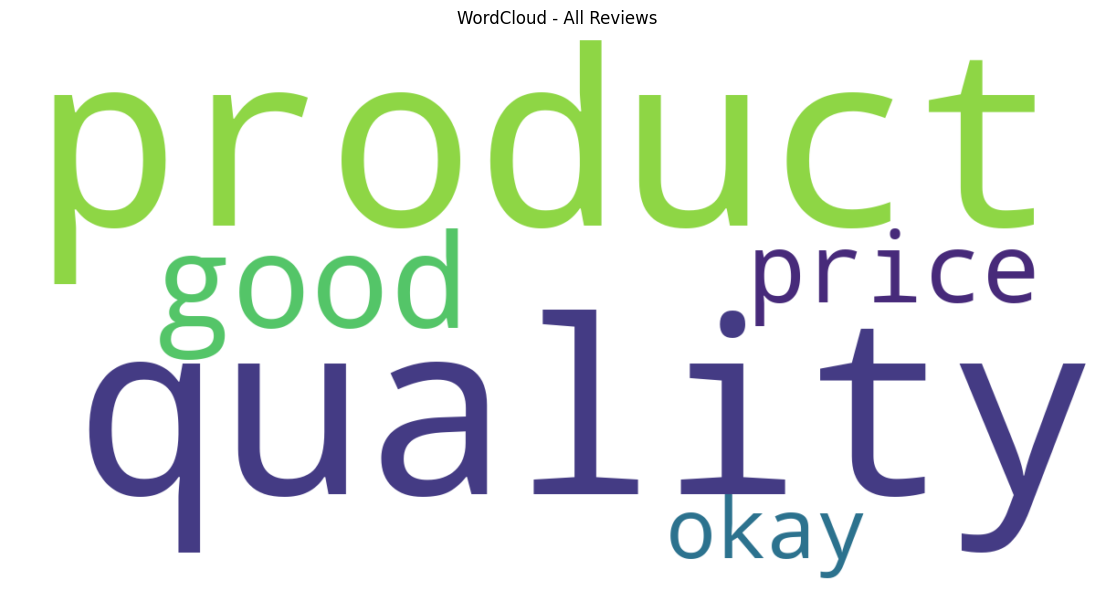

Saved: C:\Users\HP\OneDrive\Desktop\reviews.html\wordcloud_all.png


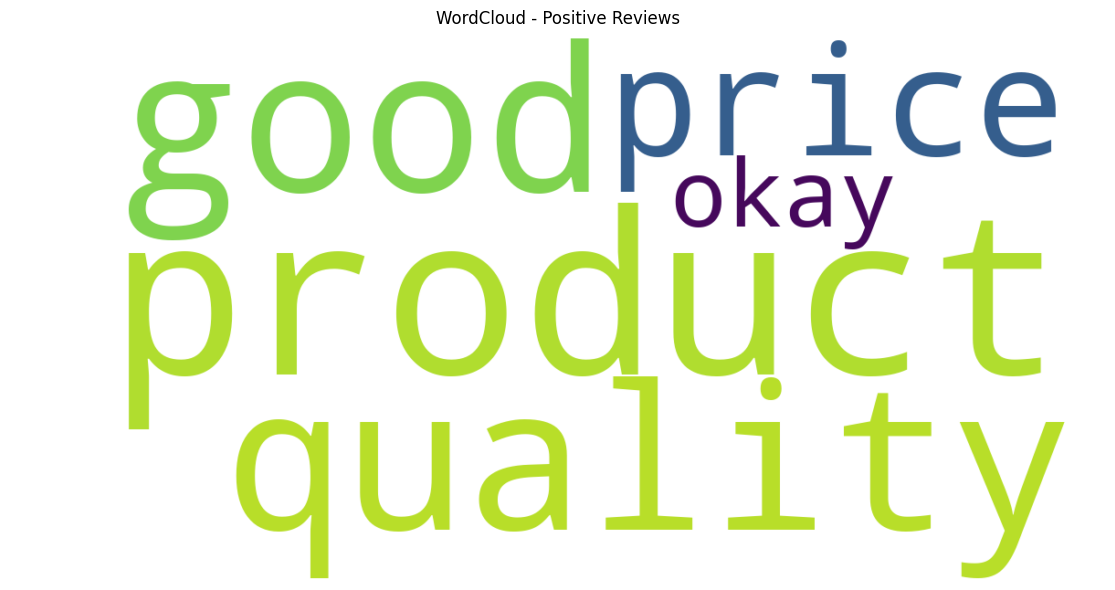

Saved: C:\Users\HP\OneDrive\Desktop\reviews.html\wordcloud_positive.png
No text available for: WordCloud - Negative Reviews


<bound method NDFrame.to_csv of                title                             review   rating sentiment
0  Excellent Product  The product quality is very good.  5 stars  Positive
1       Good Product        Good quality for the price.  4 stars  Positive
2    Average Product               The product is okay.  3 stars  Positive>

In [4]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# File paths
folder_path = r"C:\Users\HP\OneDrive\Desktop\reviews.html"
csv_path = os.path.join(folder_path, "product_reviews.csv")

# Load extracted reviews
df = pd.read_csv(csv_path)

# Check and prepare review text
if "Review Text" in df.columns:
    df["review"] = df["Review Text"].fillna("").astype(str)
elif "review" in df.columns:
    df["review"] = df["review"].fillna("").astype(str)
else:
    raise ValueError(
        "Review text column not found. Available columns: "
        + str(df.columns.tolist())
    )

# Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Classify sentiment
def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["review"].apply(classify_sentiment)

# Generate WordCloud
def generate_wordcloud(text, title, filename):
    if not text.strip():
        print("No text available for:", title)
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()

    output_path = os.path.join(folder_path, filename)
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", output_path)

# All reviews WordCloud
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text,
    "WordCloud - All Reviews",
    "wordcloud_all.png"
)

# Positive reviews WordCloud
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text,
    "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)

# Negative reviews WordCloud
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text,
    "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)

# Save analyzed reviews
output_csv = os.path.join(
    folder_path, "product_reviews_analyzed.csv"
)
df.to_csv

In [8]:
%pip install wordcloud vaderSentiment


   -------------------- ------------------- 1/2 [wordcloud]
   -------------------- ------------------- 1/2 [wordcloud]
   ---------------------------------------- 2/2 [wordcloud]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import matplotlib.pyplot as plt